# Part 2 - Deeper Analysis and Pipeline

This notebook reuses the health study dataset through a small Python module. It fits a simple linear regression for systolic blood pressure by age and compares disease prevalence by sex. These analyses describe associations in this dataset; they do not establish cause and effect.

## Load the data and analysis class

`HealthAnalyzer` keeps the analysis methods together, while `health_analyzer.py` can be reused by other Python files. The path setup below works when the notebook is opened from either the project folder or `src`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

project_root = Path.cwd()
if not (project_root / "data" / "health_study_dataset.csv").is_file():
    project_root = project_root.parent
if not (project_root / "data" / "health_study_dataset.csv").is_file():
    raise FileNotFoundError("Could not find data/health_study_dataset.csv.")

sys.path.insert(0, str(project_root / "src"))
from health_analyzer import HealthAnalyzer, load_dataset

data_path = project_root / "data" / "health_study_dataset.csv"
df = load_dataset(data_path)
analyzer = HealthAnalyzer(df)

print(f"Loaded {len(df)} participants.")
display(df.head())

Loaded 800 participants.


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


## Linear regression: age and systolic blood pressure

The model uses a NumPy design matrix and least squares to estimate the line that best fits the observed values. The slope describes the estimated blood-pressure change per additional year of age in this dataset. `R-squared` summarizes how much of the observed variation is captured by this one-predictor line.

Estimated intercept: 122.68 mmHg
Estimated slope: 0.54 mmHg per year
R-squared: 0.369


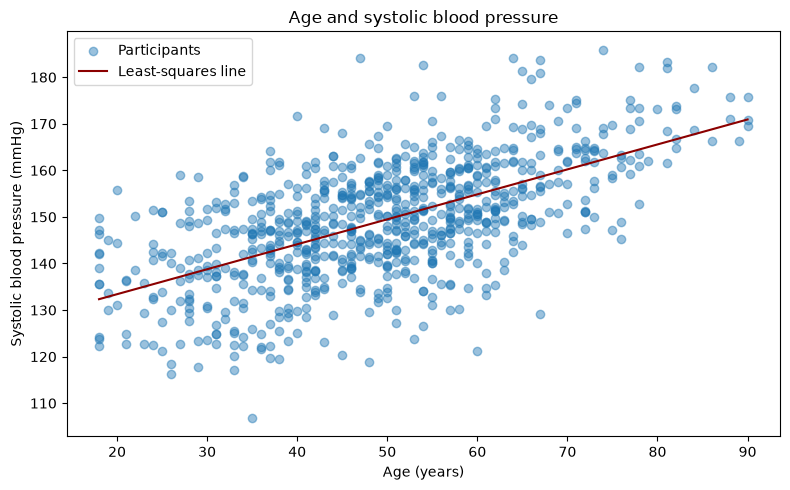

In [2]:
model = analyzer.fit_linear_regression("age", "systolic_bp")
print(f"Estimated intercept: {model['intercept']:.2f} mmHg")
print(f"Estimated slope: {model['slope']:.2f} mmHg per year")
print(f"R-squared: {model['r_squared']:.3f}")

age_line = np.linspace(df["age"].min(), df["age"].max(), 100)
bp_line = model["intercept"] + model["slope"] * age_line

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["age"], df["systolic_bp"], alpha=0.45, label="Participants")
ax.plot(age_line, bp_line, color="darkred", label="Least-squares line")
ax.set_title("Age and systolic blood pressure")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Systolic blood pressure (mmHg)")
ax.legend()
plt.tight_layout()
plt.show()

## Disease prevalence by sex

Since `disease` is coded as 0 or 1, its group mean is the proportion with disease. Multiplying by 100 gives the percentage for each sex group.

,disease_rate_percent
sex,
M,7.3
F,4.5


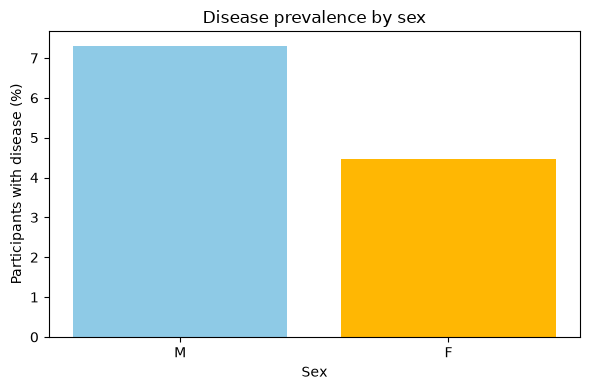

These percentages describe this dataset and do not show that sex causes disease.


In [3]:
disease_by_sex = analyzer.disease_rate_by("sex").sort_values(ascending=False)
display(disease_by_sex.round(1).to_frame())

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(disease_by_sex.index, disease_by_sex.values, color=["#8ecae6", "#ffb703"])
ax.set_title("Disease prevalence by sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Participants with disease (%)")
plt.tight_layout()
plt.show()

print("These percentages describe this dataset and do not show that sex causes disease.")

## Method choices and references

- NumPy least squares estimates the regression coefficients by minimizing squared prediction errors. The model is kept to one predictor so its slope is easy to interpret.
- Disease prevalence is calculated as the mean of a binary (0/1) outcome within each sex group, then plotted to make the comparison easy to see.
- Both results are descriptive of this study dataset; they do not establish causation or automatically generalize to other populations.

References: [NumPy `linalg.lstsq`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html), [Pandas `DataFrame.groupby`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html).

**To reproduce:** restart the notebook kernel and run all cells from top to bottom. Install the project requirements first if needed.